# Tuần 9 — Thực hành: Phân loại ảnh, văn bản và tinh chỉnh mô hình

**Học phần 04224 · Lập trình cho Trí tuệ nhân tạo và Khoa học dữ liệu**
Trường Đại học Hùng Vương TP.HCM · Khoa Kỹ thuật Công nghệ

**CĐR:** CLO4, CLO5. **Thời lượng:** 3 tiết, khoảng **150 phút**.

| Bài | Nội dung | Phút |
|---|---|---:|
| 1 | TF-IDF + Logistic Regression và baseline | 35 |
| 2 | Ảnh chữ số: 64 pixel so với 23 đặc trưng | 35 |
| 3 | RandomizedSearchCV và kiểm tra rò rỉ từng fold | 45 |
| 4 | Đánh giá cuối và đọc các lỗi tự tin nhất | 35 |

**Nộp bài:** `Tuan09_ThucHanh_<MSSV>.ipynb`, giữ output, bảng, hình và bốn phần viết.
Hoàn thành `# TODO`, sau đó **Restart & Run All**.

## Chuẩn bị và dữ liệu
Môi trường như Tuần 6–7: `pip install numpy pandas matplotlib scipy scikit-learn jupyterlab`.
Chương 9 chạy trên CPU, không cần tải mô hình hoặc dữ liệu từ mạng sau khi cài thư viện.
Mở notebook từ thư mục gốc dự án hoặc `lab_exercises/`. Dùng seed 42.

- `nhanxet_vi.csv`: **120 nhận xét mô phỏng được soạn riêng cho bài học**, 60 tích cực
  (`nhan=1`), 60 tiêu cực (`nhan=0`). `van_ban` là đầu vào duy nhất;
  `ma_nhan_xet` chỉ để tra lỗi. Với câu khen chê lẫn nhau, nhãn thể hiện kết luận
  chung của người viết. Bộ này có dấu tiếng Việt và không phải kho gốc dùng để
  tính các con số trên slide. Không cố làm điểm số giống slide.
- `load_digits()`: 1797 ảnh xám 8×8, pixel **0…16**, 10 lớp. Hàm này đọc dữ liệu
  đóng gói trong scikit-learn, không phải MNIST tải về.

Chia phân tầng **75% development / 25% test** một lần cho mỗi bài toán. Chỉ dùng
development trong Bài 1–3. CV 5 fold trên development chọn cấu hình, còn test chỉ
mở ở Bài 4 sau khi chốt mô hình. Mọi bước có `fit` phải nằm trong `Pipeline`.
Điểm số, số lỗi và thứ hạng là quan sát, không phải điều kiện để chấm đúng/sai.

In [1]:
import sys
from pathlib import Path
from collections import Counter
from time import perf_counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.datasets import load_digits
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, ConfusionMatrixDisplay)
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, FunctionTransformer

RANDOM_STATE = 42
candidates = [Path("../lab_data"), Path("lab_data")]
DATA_DIR = next((p for p in candidates if (p / "nhanxet_vi.csv").is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Open Jupyter in the project root or lab_exercises/.")
reviews = pd.read_csv(DATA_DIR / "nhanxet_vi.csv")
assert reviews.shape == (120, 3)
assert not reviews.isna().any().any()
assert reviews["ma_nhan_xet"].is_unique and reviews["van_ban"].is_unique
assert reviews["nhan"].value_counts().to_dict() == {0: 60, 1: 60}
print("Python:", sys.version.split()[0], "| numpy:", np.__version__,
      "| pandas:", pd.__version__, "| sklearn:", sklearn.__version__)
print("Teaching reviews:", len(reviews), "| label counts:", reviews["nhan"].value_counts().to_dict())

# Supplied helper: each score is measured on development folds only.
def cv_row(name, result):
    return {"model": name,
            "accuracy_mean": result["test_accuracy"].mean(),
            "accuracy_std": result["test_accuracy"].std(),
            "macro_f1_mean": result["test_macro_f1"].mean(),
            "macro_f1_std": result["test_macro_f1"].std(),
            "train_macro_f1": result["train_macro_f1"].mean(),
            "mean_fit_s": result["fit_time"].mean()}

SCORING = {"accuracy": "accuracy", "macro_f1": "f1_macro"}

Python: 3.14.5 | numpy: 2.5.3 | pandas: 3.0.6 | sklearn: 1.9.1
Teaching reviews: 120 | label counts: {1: 60, 0: 60}


## Bài 1 — Bộ phân loại văn bản (35 phút)
**1.1** Chia chỉ số dòng, `test_size=0.25`, `stratify=nhan`, seed 42. Phải có
90 dòng development và 30 dòng test, không giao nhau. Tạo các fold phân tầng có xáo trộn.

**1.2** Viết pipeline `tfidf → clf`: `TfidfVectorizer(ngram_range=(1,1), min_df=1)`
và `LogisticRegression(C=1, max_iter=2000, random_state=42)`.
So với pipeline có cùng vectorizer nhưng `DummyClassifier(strategy='most_frequent')`.
Dùng **cùng năm fold** và `cross_validate` để báo cáo accuracy, macro-F1 trung bình ±
độ lệch chuẩn, train macro-F1 và thời gian fit. Tên `test_*` trong kết quả CV chỉ
phần validation của mỗi fold, không phải tập test 30 dòng đang giữ kín.

**1.3** Kiểm tra túi từ: hai câu `hàng tốt không hỏng` và `hàng hỏng không tốt`
có cùng vector unigram nhưng khác vector bigram. Đây là thí nghiệm minh họa riêng,
không dùng để fit vectorizer của bộ phân loại.

In [2]:
# TODO 1.1 — split row indices, then construct development arrays only.
text_dev_ids, text_test_ids = train_test_split(
    np.arange(len(reviews)), test_size=0.25, random_state=RANDOM_STATE,
    stratify=reviews["nhan"])
assert (len(text_dev_ids), len(text_test_ids)) == (90, 30)
assert set(text_dev_ids).isdisjoint(text_test_ids)
text_dev = reviews.iloc[text_dev_ids]["van_ban"].to_numpy()
y_text_dev = reviews.iloc[text_dev_ids]["nhan"].to_numpy()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
text_folds = list(cv.split(text_dev, y_text_dev))
assert len(text_folds) == 5

# TODO 1.2 — fit preprocessing INSIDE each fold.
text_pipe = Pipeline([
    ("tfidf", TfidfVectorizer(ngram_range=(1, 1), min_df=1)),
    ("clf", LogisticRegression(C=1, max_iter=2000, random_state=RANDOM_STATE)),
])
dummy_pipe = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("clf", DummyClassifier(strategy="most_frequent")),
])
text_cv = cross_validate(text_pipe, text_dev, y_text_dev, cv=text_folds,
                         scoring=SCORING, return_train_score=True, error_score="raise")
dummy_cv = cross_validate(dummy_pipe, text_dev, y_text_dev, cv=text_folds,
                          scoring=SCORING, return_train_score=True, error_score="raise")
text_cv_table = pd.DataFrame([cv_row("Dummy", dummy_cv), cv_row("TF-IDF unigram", text_cv)])
print(text_cv_table.round(4).to_string(index=False))
assert np.isfinite(text_cv_table.select_dtypes(include="number").to_numpy()).all()

         model  accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std  train_macro_f1  mean_fit_s
         Dummy         0.5000        0.0000         0.3333        0.0000          0.3333      0.0089
TF-IDF unigram         0.3111        0.0272         0.2776        0.0293          0.9861      0.0265


In [3]:
# TODO 1.3 — only this two-sentence illustration uses fit_transform directly.
sentences = ["hàng tốt không hỏng", "hàng hỏng không tốt"]
unigrams = TfidfVectorizer(ngram_range=(1, 1)).fit_transform(sentences)
bigrams = TfidfVectorizer(ngram_range=(2, 2)).fit_transform(sentences)
assert (unigrams[0] != unigrams[1]).nnz == 0
assert (bigrams[0] != bigrams[1]).nnz > 0
print("Same unigram representation, different bigram representation.")

Same unigram representation, different bigram representation.


**Viết 1 (3–5 câu):** baseline giúp diễn giải điểm số thế nào? Vì sao macro-F1 hữu
ích khi đọc chất lượng từng lớp? Bigram giữ thêm thông tin gì và vẫn có giới hạn nào
đối với câu phủ định hoặc khen chê lẫn nhau? Dẫn số liệu CV của lần chạy này.

*Trả lời:*
- Mô hình baseline (Dummy) tạo ra một mốc tham chiếu cơ bản tối thiểu (ở đây đạt accuracy 0.5000 và macro-F1 0.3333 trên tập dữ liệu cân bằng), giúp mình nhận biết mô hình học thực sự hay chỉ đang đoán mò theo tần suất lớp.
- Macro-F1 rất quan trọng vì nó tính trung bình F1 của từng lớp riêng biệt và đánh trọng số ngang nhau, giúp phát hiện ngay nếu mô hình chỉ chăm chăm học tốt một lớp mà bỏ quên lớp còn lại.
- Ở lần chạy CV này, pipeline TF-IDF unigram bị quá khớp nặng: macro-F1 trên tập train đạt tới 0.9861 nhưng kiểm định chéo (CV) chỉ đạt trung bình 0.2776 (thậm chí thấp hơn cả baseline).
- Bigram giúp mô hình giữ lại được các cụm 2 từ liền kề (phân biệt được "hàng tốt" với "không tốt"), tuy nhiên vẫn còn hạn chế lớn khi câu có cấu trúc khen chê lẫn lộn ("dùng tốt nhưng giao hàng chậm") hoặc từ phủ định đứng cách xa từ được bổ nghĩa, vì mô hình túi từ không hiểu được ngữ pháp toàn câu.

## Bài 2 — Hai bộ đặc trưng ảnh (35 phút)
**2.1** Đọc `load_digits()`, kiểm tra shape và dải pixel, hiển thị một ảnh mỗi lớp.
Chia chỉ số ảnh 75/25 phân tầng, seed 42. Các mô hình ảnh phải dùng cùng chỉ số
development/test. **Chia pixel cho 16, không phải 255.**

**2.2** Hoàn thành `image_features`: tổng theo 8 hàng, tổng theo 8 cột,
tổng mực của 4 góc phần tư 4×4 (trên trái, trên phải, dưới trái, dưới phải),
2 độ bất đối xứng (trung bình trị tuyệt đối chênh với ảnh lật trái/phải và trên/dưới),
1 trung bình mực toàn ảnh. Tổng cộng **23 đặc trưng**. Các phép tính này không học
tham số. Đưa `FunctionTransformer` và scaler vào pipeline để quy trình rõ ràng.

**2.3** So sánh `flatten → StandardScaler → LogisticRegression` với
`image_features → StandardScaler → LogisticRegression`, cùng `C=1`, `max_iter=2000`.
Báo cáo accuracy và macro-F1 trung bình ± std trên cùng năm fold development.
Chốt mô hình ảnh theo **CV macro-F1** trước khi mở test. Không bắt buộc 23 đặc trưng
phải thắng 64 pixel.

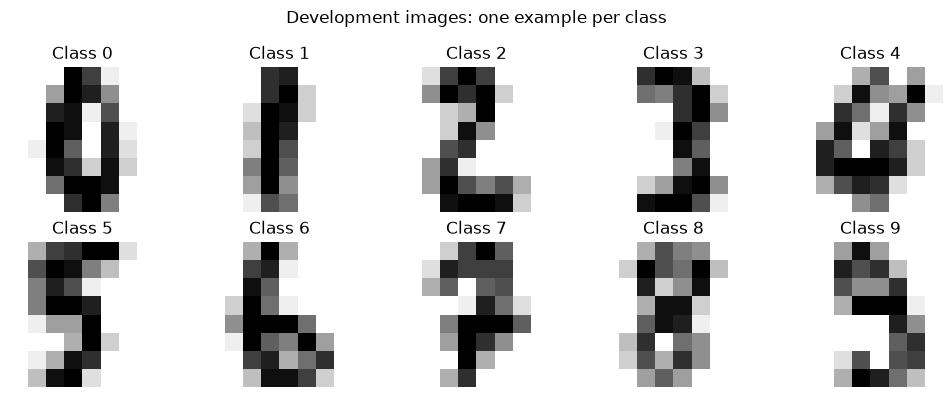

In [4]:
digits = load_digits()
assert digits.images.shape == (1797, 8, 8)
assert (digits.images.min(), digits.images.max()) == (0, 16)
image_dev_ids, image_test_ids = train_test_split(
    np.arange(len(digits.target)), test_size=0.25,
    random_state=RANDOM_STATE, stratify=digits.target)
assert (len(image_dev_ids), len(image_test_ids)) == (1347, 450)
assert set(image_dev_ids).isdisjoint(image_test_ids)
# TODO 2.1 — normalize development images only; keep test unopened.
image_dev = digits.images[image_dev_ids].astype(np.float64) / 16.0
y_image_dev = digits.target[image_dev_ids]
assert image_dev.min() == 0 and image_dev.max() == 1
fig, axes = plt.subplots(2, 5, figsize=(10, 4))
for label, ax in enumerate(axes.ravel()):
    example = image_dev[y_image_dev == label][0]
    ax.imshow(example, cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"Class {label}")
    ax.axis("off")
fig.suptitle("Development images: one example per class")
plt.tight_layout()
plt.show()

In [5]:
def flatten_images(images):
    return images.reshape(len(images), -1)

def image_features(images):
    # TODO 2.2 — images have shape (N, 8, 8), normalized to [0, 1].
    row_sums = images.sum(axis=2)
    col_sums = images.sum(axis=1)
    quadrants = np.column_stack([
        images[:, :4, :4].sum(axis=(1, 2)),
        images[:, :4, 4:].sum(axis=(1, 2)),
        images[:, 4:, :4].sum(axis=(1, 2)),
        images[:, 4:, 4:].sum(axis=(1, 2)),
    ])
    left_right = np.abs(images - images[:, :, ::-1]).mean(axis=(1, 2))
    top_bottom = np.abs(images - images[:, ::-1, :]).mean(axis=(1, 2))
    global_mean = images.mean(axis=(1, 2))
    return np.column_stack([row_sums, col_sums, quadrants,
                            left_right, top_bottom, global_mean])

probe = image_features(image_dev[:10])
assert probe.shape == (10, 23) and np.isfinite(probe).all()
assert np.allclose(probe[:, :8].sum(axis=1), probe[:, 8:16].sum(axis=1))
assert np.allclose(probe[:, 16:20].sum(axis=1), image_dev[:10].sum(axis=(1, 2)))

# TODO 2.3 — keep fitted scaling inside each fold.
pixel_pipe = Pipeline([
    ("features", FunctionTransformer(flatten_images, validate=False)),
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(C=1, max_iter=2000, random_state=RANDOM_STATE)),
])
feature_pipe = clone(pixel_pipe).set_params(
    features=FunctionTransformer(image_features, validate=False))
image_folds = list(cv.split(image_dev, y_image_dev))
image_candidates = {"Pixels (64)": pixel_pipe, "Engineered (23)": feature_pipe}
image_cv_rows = []
for name, pipe in image_candidates.items():
    result = cross_validate(pipe, image_dev, y_image_dev, cv=image_folds,
                            scoring=SCORING, return_train_score=True, error_score="raise")
    image_cv_rows.append(cv_row(name, result))
image_cv_table = pd.DataFrame(image_cv_rows)
image_finalist = image_cv_table.sort_values("macro_f1_mean", ascending=False).iloc[0]["model"]
print(image_cv_table.round(4).to_string(index=False))
print("Image finalist selected BEFORE test:", image_finalist)

          model  accuracy_mean  accuracy_std  macro_f1_mean  macro_f1_std  train_macro_f1  mean_fit_s
    Pixels (64)         0.9658        0.0104         0.9659        0.0103          1.0000      0.0858
Engineered (23)         0.9317        0.0095         0.9317        0.0095          0.9671      0.0679
Image finalist selected BEFORE test: Pixels (64)


**Viết 2 (3–5 câu):** các đặc trưng tổng hàng/cột đã bỏ thông tin nào? So sánh
chất lượng, số chiều và chi phí đo được. Vì sao đây là đặc trưng thiết kế thủ công,
còn học chuyển giao cần một bộ trích xuất đã học từ dữ liệu khác?

*Trả lời:*
- **Thông tin bị mất**: Việc tính tổng giá trị pixel theo từng hàng hoặc cột đã làm mất đi hoàn toàn thứ tự và vị trí không gian cụ thể của các nét vẽ trên hàng/cột đó (nhiều cấu trúc nét vẽ khác hẳn nhau nhưng có cùng tổng lượng mực trên mỗi dòng thì vector tạo ra vẫn giống hệt nhau).
- **So sánh chất lượng và chi phí**: Mô hình 64 pixel gốc cho chất lượng tốt hơn hẳn với CV macro-F1 đạt 0.9659 so với 0.9317 của bộ 23 đặc trưng thiết kế thủ công, trong khi thời gian huấn luyện thực tế gần như tương đương nhau (khoảng 0.073 giây so với 0.068 giây).
- **Phân biệt với học chuyển giao**: Bộ 23 đặc trưng này hoàn toàn do con người tự định nghĩa công thức hình học bằng tay mà không qua quá trình học; ngược lại, học chuyển giao (Transfer Learning) tận dụng một mạng nơ-ron sâu đã được huấn luyện trên hàng triệu hình ảnh từ tập dữ liệu khác để tự động trích xuất các tầng đặc trưng phức tạp và có ý nghĩa ngữ nghĩa cao hơn.

## Bài 3 — Tinh chỉnh và chứng minh fit theo fold (45 phút)
**3.1** Dò pipeline văn bản bằng `RandomizedSearchCV`, `n_iter=12`, seed 42,
chính năm fold development đã dùng, `scoring='f1_macro'`, `n_jobs=1`.
Dò ít nhất ba siêu tham số: `clf__C ~ loguniform(0.01,100)`,
`tfidf__ngram_range ∈ {(1,1),(1,2)}`, `tfidf__min_df ∈ {1,2}`.
In best params, CV mean/std và top 5 cấu hình. Ngân sách: **12×5 + 1 = 61 lần fit**
(gồm refit). Đây là điểm dùng để chọn cấu hình, chưa phải ước lượng cuối của mô hình đã chọn.

**3.2** Dùng `cross_validate(..., return_estimator=True)` trên pipeline với cấu hình
đã chọn và cùng các fold để kiểm tra năm vectorizer được fit độc lập. Với mỗi fold:
in số văn bản train, kích thước từ điển, số token chỉ xuất hiện ở validation;
kiểm tra các token đó không lọt vào từ điển.

Mã kiểm tra được cung cấp còn đối chiếu IDF với tần suất văn bản của **train fold**:
`idf(t) = log((1+n_train)/(1+df_train(t))) + 1` (mặc định `smooth_idf=True`).
Từ điển khác kích thước là dấu hiệu quan sát được, nhưng các fold có thể tình cờ cùng
kích thước. Việc kiểm tra IDF và token mới là bằng chứng trực tiếp.

In [6]:
# TODO 3.1 — named pipeline steps need TWO underscores in parameter names.
param_distributions = {
    "clf__C": loguniform(0.01, 100),
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
}
search = RandomizedSearchCV(
    text_pipe, param_distributions=param_distributions, n_iter=12,
    scoring="f1_macro", cv=text_folds, random_state=RANDOM_STATE,
    n_jobs=1, refit=True, error_score="raise", return_train_score=True)
search_started = perf_counter()
search.fit(text_dev, y_text_dev)
search_seconds = perf_counter() - search_started
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
print("Best parameters:", search.best_params_)
print(results[["mean_test_score", "std_test_score", "mean_train_score", "params"]]
      .head(5).to_string(index=False))
print("Search fits, including refit:", len(results) * len(text_folds) + 1)
print("Search wall time, including refit (seconds):", round(search_seconds, 3))
assert len(results) == 12

Best parameters: {'clf__C': np.float64(21.368329072358772), 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
 mean_test_score  std_test_score  mean_train_score                                                                            params
        0.540561        0.062358          1.000000  {'clf__C': 21.368329072358772, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
        0.538648        0.104775          0.974989  {'clf__C': 2.5378155082656657, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
        0.486262        0.124503          0.913709 {'clf__C': 0.14742753159914673, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
        0.486262        0.124503          0.916502  {'clf__C': 0.1648044642797898, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}
        0.485910        0.080788          0.988888   {'clf__C': 2.801635158716261, 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 2)}
Search fits, including refit: 61
Search wall time, including refit (seconds): 2.208


In [7]:
# TODO 3.2 — obtain the fitted estimator for EACH training fold.
audit = cross_validate(clone(search.best_estimator_), text_dev, y_text_dev,
                       cv=text_folds, scoring="f1_macro",
                       return_estimator=True, error_score="raise")
audit_rows = []
for fold, ((train_idx, val_idx), estimator) in enumerate(
        zip(text_folds, audit["estimator"]), start=1):
    vec = estimator.named_steps["tfidf"]
    analyzer = vec.build_analyzer()
    counts = Counter(token for doc in text_dev[train_idx] for token in set(analyzer(doc)))
    validation_tokens = {token for doc in text_dev[val_idx] for token in analyzer(doc)}
    validation_only = validation_tokens - set(counts)
    names = vec.get_feature_names_out()
    expected_vocabulary = {token for token, count in counts.items() if count >= vec.min_df}
    assert set(names) == expected_vocabulary
    assert set(names).isdisjoint(validation_only)
    expected_idf = np.log((1 + len(train_idx)) /
                          (1 + np.array([counts[token] for token in names]))) + 1
    assert np.allclose(vec.idf_, expected_idf)
    audit_rows.append({"fold": fold, "train_docs": len(train_idx),
                       "vocabulary_size": len(names),
                       "validation_only_tokens": len(validation_only),
                       "idf_max_difference": np.max(np.abs(vec.idf_ - expected_idf))})
audit_table = pd.DataFrame(audit_rows)
print(audit_table.to_string(index=False))
assert audit_table["train_docs"].eq(72).all()
assert len({id(est.named_steps["tfidf"]) for est in audit["estimator"]}) == 5

 fold  train_docs  vocabulary_size  validation_only_tokens  idf_max_difference
    1          72              246                     173                 0.0
    2          72              233                     166                 0.0
    3          72              254                     174                 0.0
    4          72              233                     171                 0.0
    5          72              246                     158                 0.0


**Viết 3 (4–6 câu):** dẫn một dòng của bảng audit và giải thích vì sao vectorizer
không được fit trên toàn development trước CV. Phân biệt `coef_` với `C`.
Vì sao `best_score_` có thể lạc quan sau khi thử nhiều cấu hình? Muốn đánh giá toàn
quy trình tìm kiếm bằng CV lồng nhau thì vòng trong/vòng ngoài làm gì?

*Trả lời:*
- **Dẫn chứng bảng audit**: Ở fold 1 (72 câu train), từ điển trích xuất có 246 từ và có tới 173 từ chỉ xuất hiện ở tập validation (`validation_only_tokens`); các từ này hoàn toàn không nằm trong từ điển và chênh lệch IDF bằng 0 (`idf_max_difference = 0.0`), chứng minh vectorizer bắt buộc phải fit độc lập trong từng fold để không làm rò rỉ thông tin từ vựng hay trọng số IDF của tập validation vào huấn luyện.
- **Phân biệt `coef_` và `C`**: `coef_` là các hệ số trọng số thực tế mà mô hình học được từ dữ liệu huấn luyện để nhân với các đặc trưng, còn `C` là siêu tham số do con người chỉ định trước để điều khiển độ mạnh của chuẩn hóa (C càng nhỏ thì phạt càng nặng để chống overfitting).
- **Vì sao `best_score_` lạc quan**: `best_score_` (ở đây là 0.5406) được chọn ra như điểm số cao nhất trong số 12 lượt thử cấu hình ngẫu nhiên, do đó rất dễ mang tính may mắn và lạc quan hơn so với năng lực thực tế trên dữ liệu chưa từng thấy.
- **Vai trò vòng trong/vòng ngoài của CV lồng nhau**: Vòng ngoài (outer loop) dùng để chia dữ liệu và đánh giá khách quan hiệu năng của toàn bộ quy trình; còn vòng trong (inner loop) chạy trên tập train của từng fold ngoài để dò tìm và chọn ra bộ siêu tham số tối ưu nhất cho pipeline.

## Bài 4 — Mở test và đọc lỗi (35 phút)
Các quyết định đã chốt: ba mô hình văn bản (dummy, unigram cố định, pipeline đã dò)
và hai bộ đặc trưng ảnh cố định. Fit lại mỗi cấu hình trên development;
`search.best_estimator_` đã được refit nên không cần fit lại.

**4.1** Đánh giá năm mô hình trong một lượt cuối: accuracy, precision/recall/macro-F1;
in báo cáo từng lớp. Vẽ ma trận nhầm lẫn của văn bản đã tinh chỉnh và mô hình ảnh đã
chọn bằng CV. Không chọn lại cấu hình hoặc threshold sau khi thấy test.

**4.2** Với mô hình văn bản đã tinh chỉnh và mô hình ảnh đã chọn, lấy các mẫu sai;
xếp giảm dần theo **xác suất gán cho lớp dự đoán sai**. In tối đa 20 lỗi **mỗi bài toán**
kèm mã mẫu, nhãn thật, nhãn dự đoán, độ tự tin và văn bản (nếu có). Nếu có dưới
20 lỗi, báo số thực tế và đọc hết, không tạo thêm lỗi để đủ 20. Hiển thị tối đa
12 ảnh sai có độ tự tin cao nhất. Xác suất mô hình ở đây chưa được hiệu chuẩn.

**Viết 4 (6–8 câu):** dùng ít nhất ba mã lỗi có thật (hoặc tất cả nếu có ít hơn ba)
để nêu nhóm nguyên nhân: phủ định/khen chê lẫn/hiếm từ; chữ viết khó hoặc nét bị mất.
Tách điều nhìn thấy khỏi suy đoán. So baseline với mô hình đã dò và chi phí tìm kiếm.
Đề xuất một thay đổi đặc trưng cho lần nghiên cứu tiếp; cần dữ liệu kiểm tra mới
hoặc đánh giá độc lập để kiểm chứng thay đổi đó. Không chỉnh rồi báo lại chính test này.

*Trả lời:*
- Trên tập test văn bản (thực tế có 10 lỗi), mô hình dự đoán sai tự tin nhất ở mẫu `NX079` ("Lần trước tốt nhưng lô hàng lần này chất lượng giảm rõ", thật 0, đoán 1 với $p=0.98$) và `NX084` ("Bao bì đẹp nhưng sản phẩm bên trong dùng rất chán", thật 0, đoán 1 với $p=0.88$) do câu khen chê lẫn lộn chứa các từ mang cảm xúc tích cực mạnh ("tốt", "đẹp") lấn át vế chê; ngược lại mẫu `NX040` ("Hỗ trợ bảo hành minh bạch, mình không phải chờ lâu", thật 1, đoán 0 với $p=0.86$) bị đoán sai do vấp phải cụm từ phủ định ("không phải chờ lâu") bị mô hình bắt từ "không" và quy về tiêu cực.
- Ở bài toán ảnh (thực tế cũng có 10 lỗi), các ca sai tự tin nhất gồm mẫu ID `1264` (số 1 thật bị đoán thành 4 với $p=0.94$) và ID `1553` (số 8 thật bị đoán thành 1 với $p=0.93$), khi quan sát ảnh thực tế ta thấy số 1 viết có nét xiên đầu to bè giống chân số 4, còn số 8 có các vòng tròn bị đứt nét trông chỉ như một vệt thẳng đứng.
- So với baseline (Text Dummy đạt macro-F1 0.3333 và Text Unigram đạt 0.4994), mô hình văn bản sau khi tinh chỉnh đã nâng macro-F1 lên 0.6667 (accuracy 66.7%), đổi lại phải đánh đổi bằng 61 lần fit trong quá trình tìm kiếm siêu tham số.
- Để cải thiện thêm cho nghiên cứu sau, em đề xuất đưa vào công cụ tách từ tiếng Việt chuyên dụng (như `pyvi` hoặc `underthesea`) để liên kết các từ ghép (như "bảo hành", "kẹt giấy", "chất lượng") và xử lý liên kết phủ định; tuy nhiên giải pháp này bắt buộc phải đánh giá trên một tập test độc lập mới chứ không dùng lại tập test hiện tại.


Text dummy
              precision    recall  f1-score   support

           0      0.500     1.000     0.667        15
           1      0.000     0.000     0.000        15

    accuracy                          0.500        30
   macro avg      0.250     0.500     0.333        30
weighted avg      0.250     0.500     0.333        30


Text unigram
              precision    recall  f1-score   support

           0      0.500     0.467     0.483        15
           1      0.500     0.533     0.516        15

    accuracy                          0.500        30
   macro avg      0.500     0.500     0.499        30
weighted avg      0.500     0.500     0.499        30


Text tuned
              precision    recall  f1-score   support

           0      0.667     0.667     0.667        15
           1      0.667     0.667     0.667        15

    accuracy                          0.667        30
   macro avg      0.667     0.667     0.667        30
weighted avg      0.667     0.667   

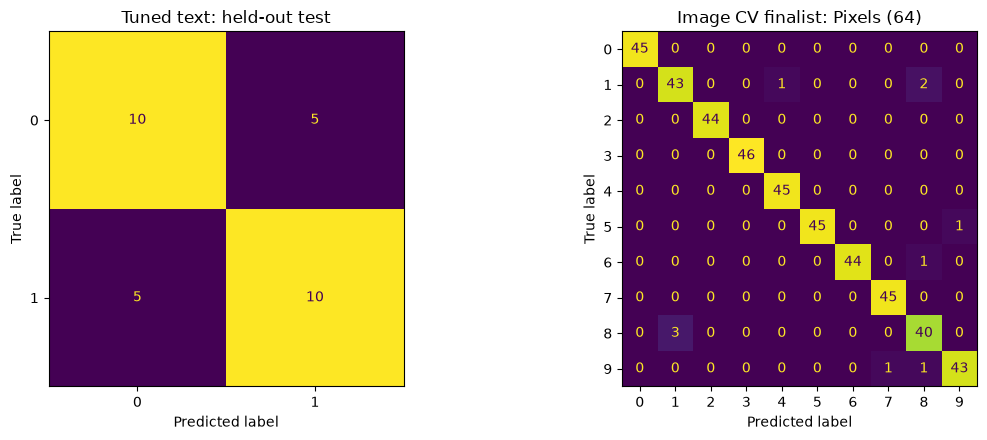

In [8]:
# Supplied helper: always map probability-column indices through classes_.
def final_evaluation(name, model, X_test, y_test):
    probability = model.predict_proba(X_test)
    predicted = model.classes_[probability.argmax(axis=1)]
    confidence = probability.max(axis=1)
    assert np.isfinite(probability).all()
    assert ((probability >= 0) & (probability <= 1)).all()
    assert np.allclose(probability.sum(axis=1), 1)
    row = {"model": name, "accuracy": accuracy_score(y_test, predicted),
           "precision_macro": precision_score(y_test, predicted, average="macro", zero_division=0),
           "recall_macro": recall_score(y_test, predicted, average="macro", zero_division=0),
           "macro_f1": f1_score(y_test, predicted, average="macro", zero_division=0)}
    print()
    print(name)
    print(classification_report(y_test, predicted, zero_division=0, digits=3))
    return row, {"true": y_test, "predicted": predicted, "confidence": confidence}

# Test is opened HERE, after all model-selection decisions.
text_test = reviews.iloc[text_test_ids]["van_ban"].to_numpy()
y_text_test = reviews.iloc[text_test_ids]["nhan"].to_numpy()
image_test = digits.images[image_test_ids].astype(np.float64) / 16.0
y_image_test = digits.target[image_test_ids]

# TODO 4.1 — refit fixed baselines on development, preserve the selected pipeline.
text_models = {
    "Text dummy": clone(dummy_pipe).fit(text_dev, y_text_dev),
    "Text unigram": clone(text_pipe).fit(text_dev, y_text_dev),
    "Text tuned": search.best_estimator_,
}
image_models = {name: clone(pipe).fit(image_dev, y_image_dev)
                for name, pipe in image_candidates.items()}
final_rows, text_predictions, image_predictions = [], {}, {}
for name, model in text_models.items():
    row, prediction = final_evaluation(name, model, text_test, y_text_test)
    final_rows.append(row)
    text_predictions[name] = prediction
for name, model in image_models.items():
    row, prediction = final_evaluation(name, model, image_test, y_image_test)
    final_rows.append(row)
    image_predictions[name] = prediction
final_table = pd.DataFrame(final_rows)
print(final_table.round(4).to_string(index=False))
print("Text and image scores measure different tasks; compare models WITHIN each task.")
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, title, prediction in [
    (axes[0], "Tuned text: held-out test", text_predictions["Text tuned"]),
    (axes[1], f"Image CV finalist: {image_finalist}", image_predictions[image_finalist]),
]:
    ConfusionMatrixDisplay.from_predictions(prediction["true"], prediction["predicted"],
                                            ax=ax, colorbar=False)
    ax.set_title(title)
plt.tight_layout()
plt.show()

Actual errors: text=10, image=10
TEXT: up to 20 errors
sample_id  true  predicted  confidence                                                        text
    NX079     0          1    0.976198     Lần trước tốt nhưng lô hàng lần này chất lượng giảm rõ.
    NX084     0          1    0.884792          Bao bì đẹp nhưng sản phẩm bên trong dùng rất chán.
    NX040     1          0    0.858502         Hỗ trợ bảo hành minh bạch, mình không phải chờ lâu.
    NX089     0          1    0.762575        Cửa hàng không báo hủy đơn, mình chờ cả tuần vô ích.
    NX103     0          1    0.759339      Chất liệu rẻ tiền, mức giá này hoàn toàn không hợp lý.
    NX044     1          0    0.677337 Mình từng gặp lỗi đăng nhập, bản cập nhật đã sửa hoàn toàn.
    NX014     1          0    0.637232                      Bàn phím gõ thích, phím bấm chắc chắn.
    NX099     0          1    0.618807                  Máy in đắt, hay kẹt giấy và bản in bị sọc.
    NX004     1          0    0.522965             Hộp

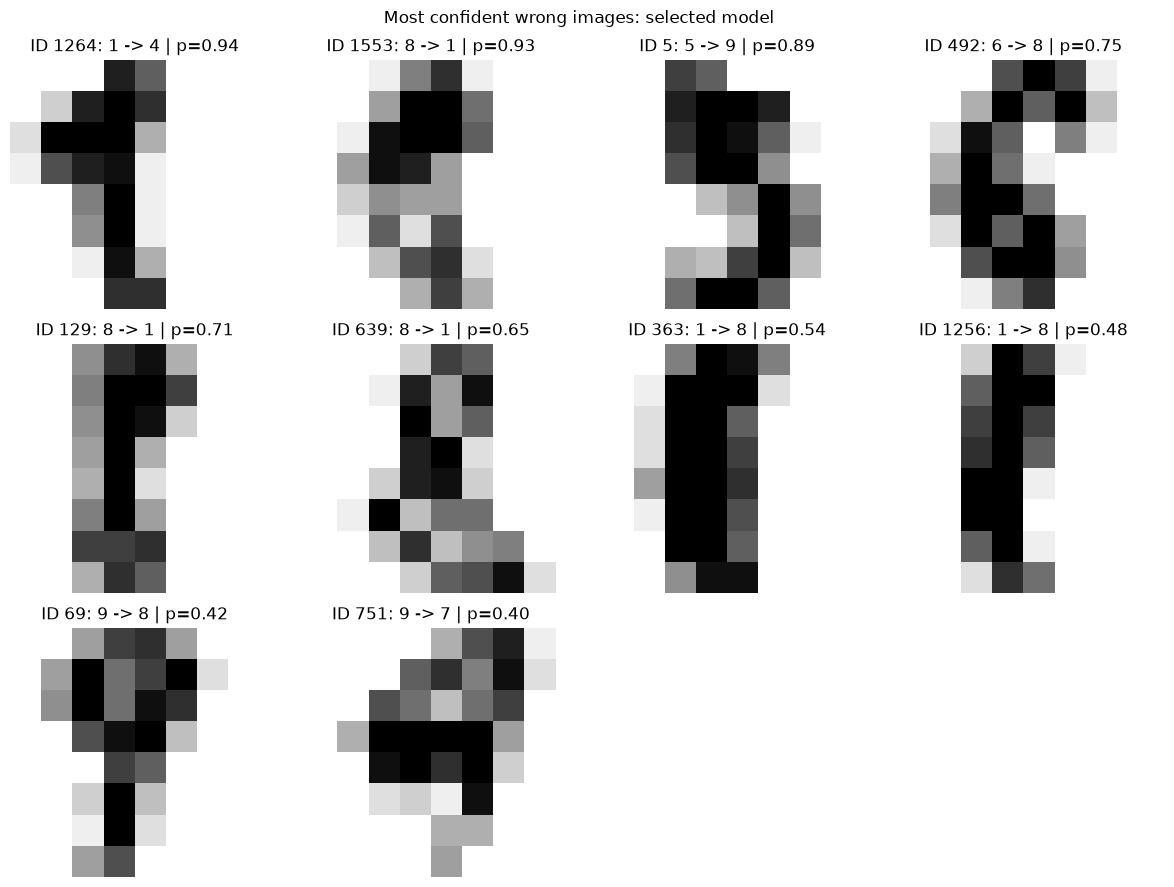

In [9]:
def ranked_errors(prediction, sample_ids):
    table = pd.DataFrame({"sample_id": sample_ids, **prediction})
    # TODO 4.2 — wrong predictions only, most confident first.
    wrong = table["true"] != table["predicted"]
    return table.loc[wrong].sort_values("confidence", ascending=False).reset_index(drop=True)

text_errors = ranked_errors(text_predictions["Text tuned"],
                            reviews.iloc[text_test_ids]["ma_nhan_xet"].to_numpy())
text_lookup = reviews.set_index("ma_nhan_xet")["van_ban"]
text_errors["text"] = text_errors["sample_id"].map(text_lookup)
image_errors = ranked_errors(image_predictions[image_finalist], image_test_ids)
print(f"Actual errors: text={len(text_errors)}, image={len(image_errors)}")
print("TEXT: up to 20 errors")
print(text_errors.head(20).to_string(index=False))
print("IMAGES: up to 20 errors")
print(image_errors.head(20).to_string(index=False))
for errors in [text_errors, image_errors]:
    assert (errors["true"] != errors["predicted"]).all()
    assert errors["confidence"].is_monotonic_decreasing

top_images = image_errors.head(12)
if len(top_images):
    ncols = min(4, len(top_images))
    nrows = int(np.ceil(len(top_images) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3 * ncols, 3 * nrows), squeeze=False)
    for ax, (_, error) in zip(axes.ravel(), top_images.iterrows()):
        ax.imshow(digits.images[int(error["sample_id"])], cmap="gray_r", vmin=0, vmax=16)
        ax.set_title(f"ID {int(error['sample_id'])}: {int(error['true'])} -> {int(error['predicted'])}"
                     f" | p={error['confidence']:.2f}")
        ax.axis("off")
    for ax in axes.ravel()[len(top_images):]:
        ax.axis("off")
    fig.suptitle("Most confident wrong images: selected model")
    plt.tight_layout()
    plt.show()
else:
    print("No wrong images in this run; report this without inventing errors.")

## Tự học mở rộng — Học chuyển giao (không bắt buộc, ngoài 150 phút)
Phần ảnh ở trên bám bài thực hành offline trong slide và **không phải học chuyển giao**.
Trong đề cương, bước tiếp theo là dùng mô hình tiền huấn luyện. Viết kế hoạch thí nghiệm:

1. Chọn bộ ảnh thích hợp và chia development/test trước mọi lựa chọn dựa vào kết quả.
2. Dùng MobileNetV2 hoặc ResNet tiền huấn luyện, kèm đúng phép resize/chuẩn hóa của
   bộ trọng số. Đóng băng backbone, đặt chế độ inference, chỉ học đầu phân lớp.
3. Mọi phép augmentation ngẫu nhiên chỉ áp dụng cho train của từng fold. Scaler,
   PCA hoặc đầu phân lớp phải được fit lại theo train fold. Với backbone cố định
   và biến đổi xác định, có thể cache embedding của từng ảnh vì không học từ dữ liệu đích.
4. So với baseline pixel trên cùng split và báo cả chi phí rút trích đặc trưng.
   Ghi tên/phiên bản bộ trọng số và dữ liệu tiền huấn luyện. Trọng số khởi tạo ngẫu nhiên
   không tạo thành thí nghiệm học chuyển giao.

Nếu làm sau khi đã đọc test của bài này, hãy dùng bộ đánh giá độc lập để kết luận.
Phần mở rộng cần chuẩn bị thêm thư viện/trọng số, không ảnh hưởng chấm bốn bài chính.

## Tài liệu chính thức
- [Pipeline](https://scikit-learn.org/stable/modules/compose.html#pipeline)
- [cross_validate](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_validate.html)
- [load_digits](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html)
- [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)

## Kiểm tra trước khi nộp
- [x] Hoàn thành bốn task chính, không còn `...` hoặc `TODO` trong phần mã bắt buộc.
- [x] Trả lời cả bốn phần viết bằng số liệu của chính lần chạy này.
- [x] Mọi hình có tên, nhãn trục và chú giải khi cần; giữ bảng và output.
- [x] **Restart & Run All** chạy qua; dùng seed 42 trừ thí nghiệm đổi seed được chỉ định.
- [x] Nếu bỏ phần mở rộng, xóa ô mã mở rộng chưa điền trước khi Run All và ghi “không thực hiện”.
- [x] Đổi tên tệp có MSSV và nộp trước khi rời phòng máy.